**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332

---

**Practical Assignment 3: Performance Evaluation of Regression Model**


---

**1. Aim:**

- To develop different regression models for a real-world application of house price prediction.

- To evaluate regression models using Mean Squared Error (MSE), Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

- To implement Gradient Descent optimization for Linear Regression.

- To analyze the effect of learning rate and iterations on model convergence.

- To compare the performance of manually implemented Gradient Descent with the standard Linear Regression model.

---

**2. Theory:**

**2.1. Introduction:**

Regression is a supervised machine learning technique used to predict continuous numerical values based on one or more independent variables.

In this experiment, regression models are used to predict house prices based on housing characteristics such as median income, house age, number of rooms, population, and geographical location.

**Types of Regression Used:**

**1. Simple Linear Regression**

It predicts the target variable using a single independent variable.

Equation:

ŷ = mx + c

Where:
- x = Independent variable
- ŷ = Predicted value
- m = Slope
- c = Intercept

**2. Multiple Linear Regression**

It predicts the target variable using multiple independent variables.

Equation:

ŷ = b₀ + b₁x₁ + b₂x₂ + ... + bₙxₙ

**3. Polynomial Regression**

It models nonlinear relationships by introducing higher powers of input variables.

For degree 2:

ŷ = b₀ + b₁x + b₂x²

**2.2. Gradient Descent Optimization:**

Gradient Descent is an iterative optimization algorithm used to minimize the cost function by updating model parameters in the direction opposite to the gradient.

For Linear Regression:

J(w,b) = (1/n) Σ (ŷᵢ - yᵢ)²

Gradients:

∂J/∂w = (2/n) Σ (ŷᵢ - yᵢ)xᵢ

∂J/∂b = (2/n) Σ (ŷᵢ - yᵢ)

Parameter updates:

w = w - α(∂J/∂w)

b = b - α(∂J/∂b)

Where α represents the learning rate.

**2.3. Performance Evaluation Metrics:**

- **MSE:** Measures the average squared difference between actual and predicted values.
- **MAE:** Measures the average absolute prediction error.
- **RMSE:** Represents prediction error in the same unit as the target.
- **R² Score:** Measures how much variation in the target variable is explained by the model.

A lower MSE, MAE and RMSE indicate better predictions, while an R² score closer to 1 indicates a better fit.

---

**3. Import Libraries:**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


**4. Load the Dataset:**

In [ ]:
# Load California Housing Dataset

housing = fetch_california_housing(as_frame=True)

df = housing.frame

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


**5. Dataset Exploration and Preprocessing:**

In [ ]:
# Display dataset information

print("Column Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

Column Names:
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude', 'MedHouseVal']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB

Missing Values:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

Statistical Summary:


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [ ]:
# Check and handle missing values

print("Missing values before cleaning:",
      df.isnull().sum().sum())

df = df.dropna()

print("Missing values after cleaning:",
      df.isnull().sum().sum())

print("\nDataset Shape after cleaning:", df.shape)

Missing values before cleaning: 0
Missing values after cleaning: 0

Dataset Shape after cleaning: (20640, 9)


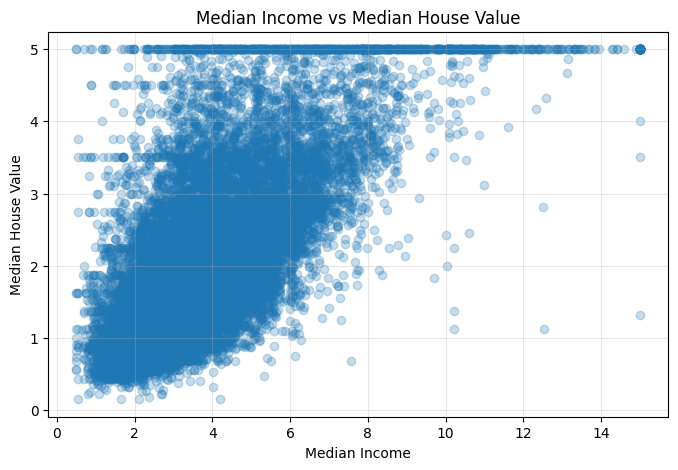

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df['MedInc'],
    df['MedHouseVal'],
    alpha=0.25
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Median Income vs Median House Value")
plt.grid(alpha=0.3)

plt.show()

**Observation:**

The scatter plot shows a positive relationship between median income and median house value. As median income increases, house prices generally increase. This makes median income a suitable feature for Simple Linear Regression.

---

**6. Prepare Training and Testing Data:**



In [ ]:
# Define independent and dependent variables

X = df.drop('MedHouseVal', axis=1)
y = df['MedHouseVal']

# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Features:", X.shape[1])

Training Samples: 16512
Testing Samples: 4128
Number of Features: 8


**Part A: Develop Regression Models**

---

**7. Simple Linear Regression:**

**Theory:**

Simple Linear Regression uses one independent variable to predict a continuous dependent variable.

**In this experiment:**
- Independent variable: MedInc
- Dependent variable: MedHouseVal
Mathematical equation:
\[
y=mx+c
\]

In [ ]:
# Select one feature

X_simple_train = X_train[['MedInc']]
X_simple_test = X_test[['MedInc']]

# Create and train the model

simple_model = LinearRegression()

simple_model.fit(X_simple_train, y_train)

# Make predictions

y_pred_simple = simple_model.predict(X_simple_test)

# Display model parameters

print("Simple Linear Regression")
print("Slope:", simple_model.coef_[0])
print("Intercept:", simple_model.intercept_)

# Evaluate model

print("\nPerformance Metrics:")
print("MSE:", mean_squared_error(y_test, y_pred_simple))
print("MAE:", mean_absolute_error(y_test, y_pred_simple))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_simple)))
print("R2 Score:", r2_score(y_test, y_pred_simple))

Simple Linear Regression
Slope: 0.4193384939381271
Intercept: 0.4445972916907879

Performance Metrics:
MSE: 0.7091157771765549
MAE: 0.629908653009376
RMSE: 0.8420901241414455
R2 Score: 0.45885918903846656


**Plot Regression Line:**

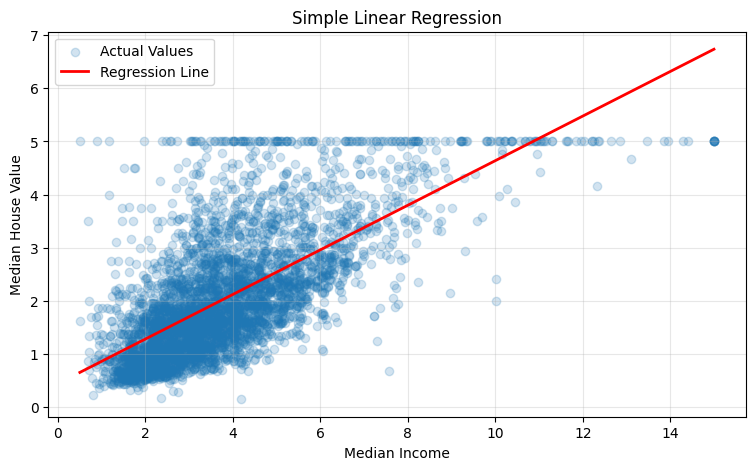

In [ ]:
# Sort values for plotting the regression line

order = np.argsort(X_simple_test['MedInc'].values)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_simple_test['MedInc'],
    y_test,
    alpha=0.2,
    label='Actual Values'
)

plt.plot(
    X_simple_test['MedInc'].values[order],
    y_pred_simple[order],
    color='red',
    linewidth=2,
    label='Regression Line'
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Simple Linear Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Observation:**

The regression line represents the relationship between median income and house value. The distance between actual points and the regression line represents prediction errors.

---

**8. Multiple Linear Regression:**

**Theory:**

Multiple Linear Regression uses more than one independent variable to predict the target variable.

In this experiment, all eight housing features are used to predict median house value.
\[
y = b_0+b_1x_1+b_2x_2+....+b_8x_8
\]

In [ ]:
# Create Multiple Linear Regression model

multiple_model = LinearRegression()

# Train model

multiple_model.fit(X_train, y_train)

# Predict house prices

y_pred_multiple = multiple_model.predict(X_test)

# Display model parameters

print("Multiple Linear Regression")
print("Intercept:", multiple_model.intercept_)

print("\nFeature Coefficients:")

for feature, coefficient in zip(
    X.columns,
    multiple_model.coef_
):
    print(feature, ":", coefficient)

# Evaluate performance

print("\nPerformance Metrics:")
print("MSE:", mean_squared_error(y_test, y_pred_multiple))
print("MAE:", mean_absolute_error(y_test, y_pred_multiple))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_multiple)))
print("R2 Score:", r2_score(y_test, y_pred_multiple))

Multiple Linear Regression
Intercept: -37.02327770606405

Feature Coefficients:
MedInc : 0.4486749096657175
HouseAge : 0.009724257517905038
AveRooms : -0.12332334282795937
AveBedrms : 0.7831449067929716
Population : -2.0296205801330347e-06
AveOccup : -0.003526318487134326
Latitude : -0.4197924865883591
Longitude : -0.4337080649639867

Performance Metrics:
MSE: 0.5558915986952438
MAE: 0.5332001304956561
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512


**Actual vs Predicted Values**

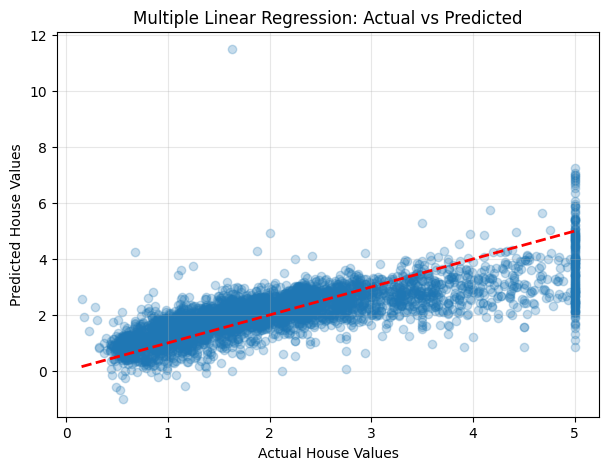

In [ ]:
plt.figure(figsize=(7, 5))

plt.scatter(
    y_test,
    y_pred_multiple,
    alpha=0.25
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--',
    linewidth=2
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid(alpha=0.3)

plt.show()

**Observation:**

Multiple Linear Regression considers several housing characteristics simultaneously. It can capture more information than Simple Linear Regression and may achieve better prediction performance.

---

**9. Polynomial Regression:**

**Theory:**

Polynomial Regression is used when the relationship between input and output variables is nonlinear.

It extends Linear Regression by adding polynomial terms such as \(x^2\).

For degree 2:
\[
y=b_0+b_1x+b_2x^2
\]

Here, we use Median Income as the independent variable.

In [ ]:
# Create Polynomial Regression model of degree 2

polynomial_model = make_pipeline(
    PolynomialFeatures(degree=2),
    StandardScaler(),
    Ridge(alpha=1.0)
)

# Train model

polynomial_model.fit(X_simple_train, y_train)

# Predict values

y_pred_polynomial = polynomial_model.predict(X_simple_test)

# Evaluate model

print("Polynomial Regression (Degree 2)")

print("MSE:", mean_squared_error(y_test, y_pred_polynomial))
print("MAE:", mean_absolute_error(y_test, y_pred_polynomial))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_polynomial)))
print("R2 Score:", r2_score(y_test, y_pred_polynomial))

Polynomial Regression (Degree 2)
MSE: 0.7032715675121511
MAE: 0.6282916122746668
RMSE: 0.8386128829872286
R2 Score: 0.4633190254417924


**Plot Polynomial Regression**

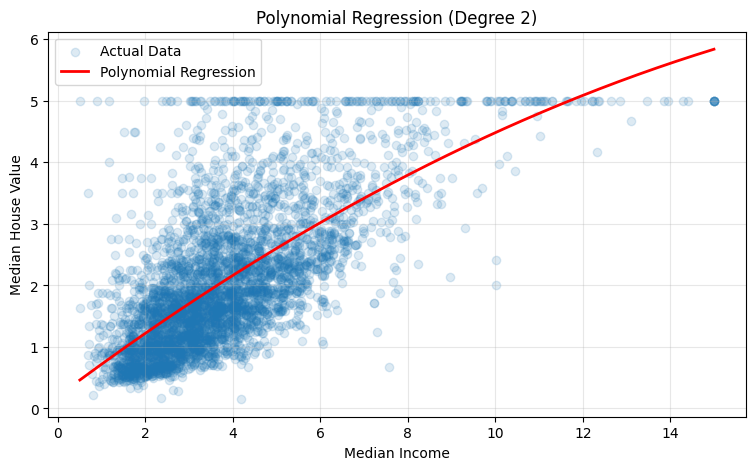

In [ ]:
# Generate sorted input values

x_grid = np.linspace(
    X_simple_train['MedInc'].min(),
    X_simple_train['MedInc'].max(),
    300
).reshape(-1, 1)

# Generate predictions

y_grid = polynomial_model.predict(x_grid)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_simple_test['MedInc'],
    y_test,
    alpha=0.15,
    label="Actual Data"
)

plt.plot(
    x_grid,
    y_grid,
    color='red',
    linewidth=2,
    label="Polynomial Regression"
)

plt.xlabel("Median Income")
plt.ylabel("Median House Value")
plt.title("Polynomial Regression (Degree 2)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Observation:**

Polynomial Regression can capture curved relationships between median income and house values. However, increasing model complexity does not always improve generalization.

---

**10. Compare Regression Models:**

This section compares all three models using the same testing dataset and evaluation metrics.

In [ ]:
# Prepare model comparison

results = {
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression'
    ],

    'MSE': [
        mean_squared_error(y_test, y_pred_simple),
        mean_squared_error(y_test, y_pred_multiple),
        mean_squared_error(y_test, y_pred_polynomial)
    ],

    'MAE': [
        mean_absolute_error(y_test, y_pred_simple),
        mean_absolute_error(y_test, y_pred_multiple),
        mean_absolute_error(y_test, y_pred_polynomial)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_simple)),
        np.sqrt(mean_squared_error(y_test, y_pred_multiple)),
        np.sqrt(mean_squared_error(y_test, y_pred_polynomial))
    ],

    'R2 Score': [
        r2_score(y_test, y_pred_simple),
        r2_score(y_test, y_pred_multiple),
        r2_score(y_test, y_pred_polynomial)
    ]
}

comparison_df = pd.DataFrame(results)

display(comparison_df.round(4))

,Model,MSE,MAE,RMSE,R2 Score
0,Simple Linear Regression,0.7091,0.6299,0.8421,0.4589
1,Multiple Linear Regression,0.5559,0.5332,0.7456,0.5758
2,Polynomial Regression,0.7033,0.6283,0.8386,0.4633


**Visual Comparison**

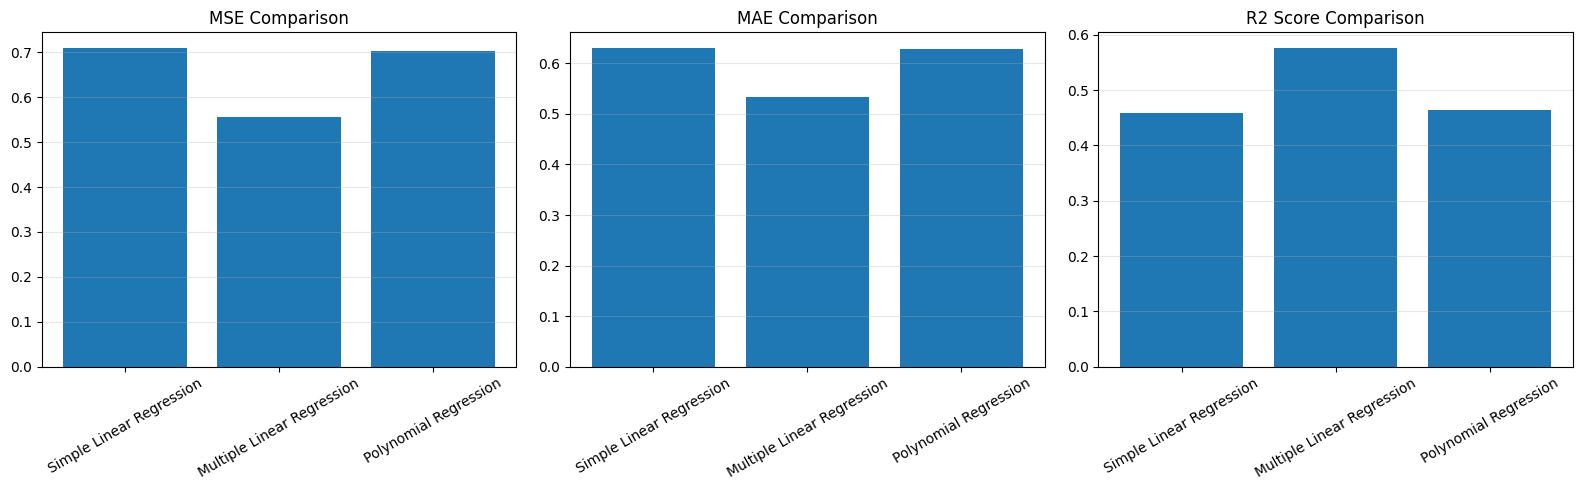

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ['MSE', 'MAE', 'R2 Score']

for ax, metric in zip(axes, metrics):

    ax.bar(
        comparison_df['Model'],
        comparison_df[metric]
    )

    ax.set_title(metric + " Comparison")
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:**
- Lower MSE indicates fewer large prediction errors.
- Lower MAE indicates better average prediction accuracy.
- Lower RMSE indicates smaller prediction errors in the original target unit.
- Higher R² indicates that the model explains more variation in house prices.
The model with the lowest errors and highest R² can be considered the strongest candidate, subject to validation and generalization.

---

**Part B: Implement and Analyze Gradient Descent for Linear Regression**

---

**11. Gradient Descent Theory:**

Gradient Descent is an optimization algorithm used to find the best parameters of a regression model by minimizing the Mean Squared Error (MSE).

Unlike ordinary Linear Regression, which calculates the parameters directly using mathematical optimization, Gradient Descent repeatedly updates weights and bias until the error becomes sufficiently small.

---

**12. Data Standardization:**

Standardization transforms input features to have approximately zero mean and unit standard deviation.

It is important because the housing features have different numerical scales. Without standardization, Gradient Descent may converge slowly or become unstable.

In [ ]:
# Standardize input features

scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

# Standardize target variable

y_mean = y_train.mean()
y_std = y_train.std()

y_train_scaled = (y_train.values - y_mean) / y_std
y_test_scaled = (y_test.values - y_mean) / y_std

print("Feature standardization completed!")
print("Training feature shape:", X_train_scaled.shape)
print("Testing feature shape:", X_test_scaled.shape)

Feature standardization completed!
Training feature shape: (16512, 8)
Testing feature shape: (4128, 8)


**13. Implement Gradient Descent Manually:**

Here, we implement Batch Gradient Descent using NumPy without using any machine learning optimization algorithm.

The model uses all eight independent variables.

In [ ]:
# Initialize parameters

n_samples, n_features = X_train_scaled.shape

weights = np.zeros(n_features)
bias = 0.0

# Set hyperparameters

learning_rate = 0.05
epochs = 1000

loss_history = []

# Batch Gradient Descent

for epoch in range(epochs):

    # Calculate predictions

    y_pred = np.dot(X_train_scaled, weights) + bias

    # Calculate errors

    error = y_pred - y_train_scaled

    # Calculate Mean Squared Error

    loss = np.mean(error ** 2)

    loss_history.append(loss)

    # Calculate gradients

    dw = (2 / n_samples) * np.dot(
        X_train_scaled.T, error
    )

    db = (2 / n_samples) * np.sum(error)

    # Update weights and bias

    weights = weights - learning_rate * dw

    bias = bias - learning_rate * db

# Display final parameters

print("Gradient Descent Training Completed!")

print("\nFinal Weights:")
print(weights)

print("\nFinal Bias:")
print(bias)

print("\nFinal Training MSE:")
print(loss_history[-1])

Gradient Descent Training Completed!

Final Weights:
[ 0.73985107  0.10620478 -0.25620983  0.29467319 -0.00192759 -0.03535567
 -0.77336858 -0.75004515]

Final Bias:
4.2734872488282265e-15

Final Training MSE:
0.3874260958147746


**Explanation of implementation:**
1. Initially, all weights and bias are set to zero.
2. Predictions are generated using the current parameters.
3. Prediction errors are calculated.
4. Gradients are calculated using the derivatives of MSE.
5. Weights and bias are updated using the learning rate.
6. The process repeats for 1000 epochs.

---

**14. Plot Gradient Descent Loss Curve:**

The loss curve helps us understand whether the algorithm is successfully minimizing the prediction error.

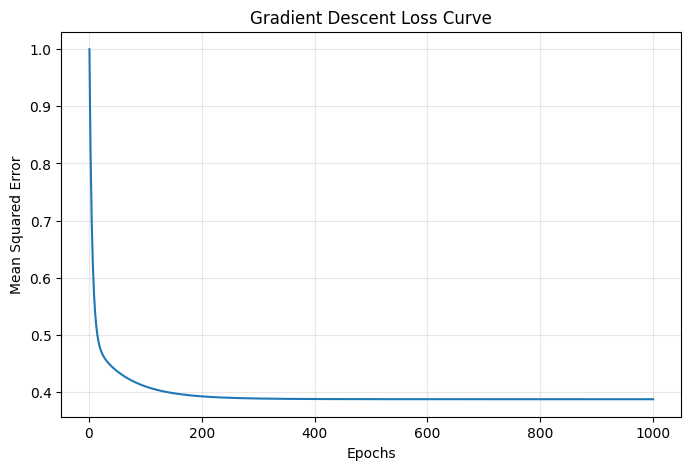

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history
)

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Gradient Descent Loss Curve")
plt.grid(alpha=0.3)

plt.show()

**Observation:**
- Initially, the loss is relatively high.
- As the number of epochs increases, the loss decreases.
- The curve gradually becomes flatter.
- A flattening curve indicates convergence towards a minimum of the cost function.

---

**15. Evaluate Gradient Descent Model:**

After training, we use the learned weights and bias to predict house prices on unseen testing data.

Since the target variable was standardized during training, we convert predictions back to the original scale.

In [ ]:
# Predict using Gradient Descent

y_pred_gd_scaled = (
    np.dot(X_test_scaled, weights) + bias
)

# Convert predictions to original scale

y_pred_gd = (
    y_pred_gd_scaled * y_std + y_mean
)

# Calculate performance metrics

gd_mse = mean_squared_error(y_test, y_pred_gd)
gd_mae = mean_absolute_error(y_test, y_pred_gd)
gd_rmse = np.sqrt(gd_mse)
gd_r2 = r2_score(y_test, y_pred_gd)

print("GRADIENT DESCENT - PERFORMANCE")

print("MSE:", gd_mse)
print("MAE:", gd_mae)
print("RMSE:", gd_rmse)
print("R2 Score:", gd_r2)

GRADIENT DESCENT - PERFORMANCE
MSE: 0.5559984462926858
MAE: 0.5331647545166763
RMSE: 0.745653033449664
R2 Score: 0.5757061684367721


**16. Compare Gradient Descent with Linear Regression:**

We compare our manually implemented Gradient Descent model with the standard Scikit-learn Linear Regression model.

In [ ]:
# Train standard Linear Regression

standard_model = LinearRegression()

standard_model.fit(X_train_scaled, y_train_scaled)

# Predict using standard Linear Regression

y_pred_standard_scaled = standard_model.predict(
    X_test_scaled
)

# Convert predictions to original scale

y_pred_standard = (
    y_pred_standard_scaled * y_std + y_mean
)

# Create comparison table

gd_comparison = pd.DataFrame({

    'Model': [
        'Gradient Descent',
        'Scikit-learn Linear Regression'
    ],

    'MSE': [
        mean_squared_error(y_test, y_pred_gd),
        mean_squared_error(y_test, y_pred_standard)
    ],

    'MAE': [
        mean_absolute_error(y_test, y_pred_gd),
        mean_absolute_error(y_test, y_pred_standard)
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_gd)),
        np.sqrt(mean_squared_error(y_test, y_pred_standard))
    ],

    'R2 Score': [
        r2_score(y_test, y_pred_gd),
        r2_score(y_test, y_pred_standard)
    ]

})

display(gd_comparison.round(5))

,Model,MSE,MAE,RMSE,R2 Score
0,Gradient Descent,0.55600,0.53316,0.74565,0.57571
1,Scikit-learn Linear Regression,0.55589,0.53320,0.74558,0.57579


**Observation:**

Both methods optimize the Linear Regression objective. When Gradient Descent converges sufficiently, its results should be close to those of standard Linear Regression. Minor differences may occur because Gradient Descent uses a finite number of iterations.

---

**17. Analyze the Effect of Learning Rate:**

The learning rate controls the size of parameter updates during Gradient Descent.
- A very small learning rate results in slow convergence.
- An appropriate learning rate provides stable convergence.
- A very large learning rate may cause oscillation or divergence.

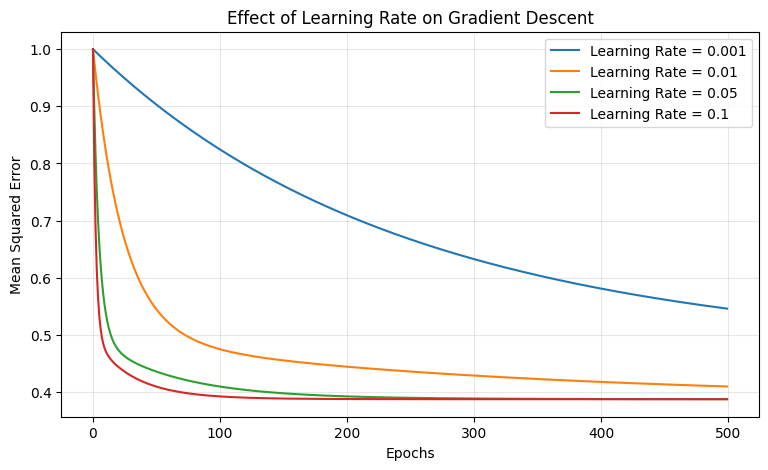

In [ ]:
# Function to perform Gradient Descent

def gradient_descent(X, y, lr, epochs):

    n, features = X.shape

    w = np.zeros(features)
    b = 0.0

    history = []

    for i in range(epochs):

        prediction = np.dot(X, w) + b

        error = prediction - y

        loss = np.mean(error ** 2)

        history.append(loss)

        dw = (2 / n) * np.dot(X.T, error)

        db = (2 / n) * np.sum(error)

        w = w - lr * dw

        b = b - lr * db

    return w, b, history


# Compare learning rates

learning_rates = [0.001, 0.01, 0.05, 0.1]

plt.figure(figsize=(9, 5))

for lr in learning_rates:

    w, b, history = gradient_descent(
        X_train_scaled,
        y_train_scaled,
        lr,
        500
    )

    plt.plot(
        history,
        label=f"Learning Rate = {lr}"
    )

plt.xlabel("Epochs")
plt.ylabel("Mean Squared Error")
plt.title("Effect of Learning Rate on Gradient Descent")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Analysis:**

The learning rate influences how quickly Gradient Descent approaches the minimum loss. A suitable learning rate provides a balance between convergence speed and stability. The plotted curves help identify which learning rate performs best for this dataset.

---

**Part C: Final Comparison and Evaluation**

---
**18. Compare All Implemented Models:**

This section combines the results of all regression models and Gradient Descent to identify the most suitable model for house price prediction.

In [ ]:
# Final comparison of all models

final_results = pd.DataFrame({

    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression',
        'Polynomial Regression',
        'Gradient Descent'
    ],

    'MSE': [
        mean_squared_error(y_test, y_pred_simple),
        mean_squared_error(y_test, y_pred_multiple),
        mean_squared_error(y_test, y_pred_polynomial),
        gd_mse
    ],

    'MAE': [
        mean_absolute_error(y_test, y_pred_simple),
        mean_absolute_error(y_test, y_pred_multiple),
        mean_absolute_error(y_test, y_pred_polynomial),
        gd_mae
    ],

    'RMSE': [
        np.sqrt(mean_squared_error(y_test, y_pred_simple)),
        np.sqrt(mean_squared_error(y_test, y_pred_multiple)),
        np.sqrt(mean_squared_error(y_test, y_pred_polynomial)),
        gd_rmse
    ],

    'R2 Score': [
        r2_score(y_test, y_pred_simple),
        r2_score(y_test, y_pred_multiple),
        r2_score(y_test, y_pred_polynomial),
        gd_r2
    ]

})

display(final_results.round(5))

,Model,MSE,MAE,RMSE,R2 Score
0,Simple Linear Regression,0.70912,0.62991,0.84209,0.45886
1,Multiple Linear Regression,0.55589,0.53320,0.74558,0.57579
2,Polynomial Regression,0.70327,0.62829,0.83861,0.46332
3,Gradient Descent,0.55600,0.53316,0.74565,0.57571


**19. Visualize Final Model Comparison:**

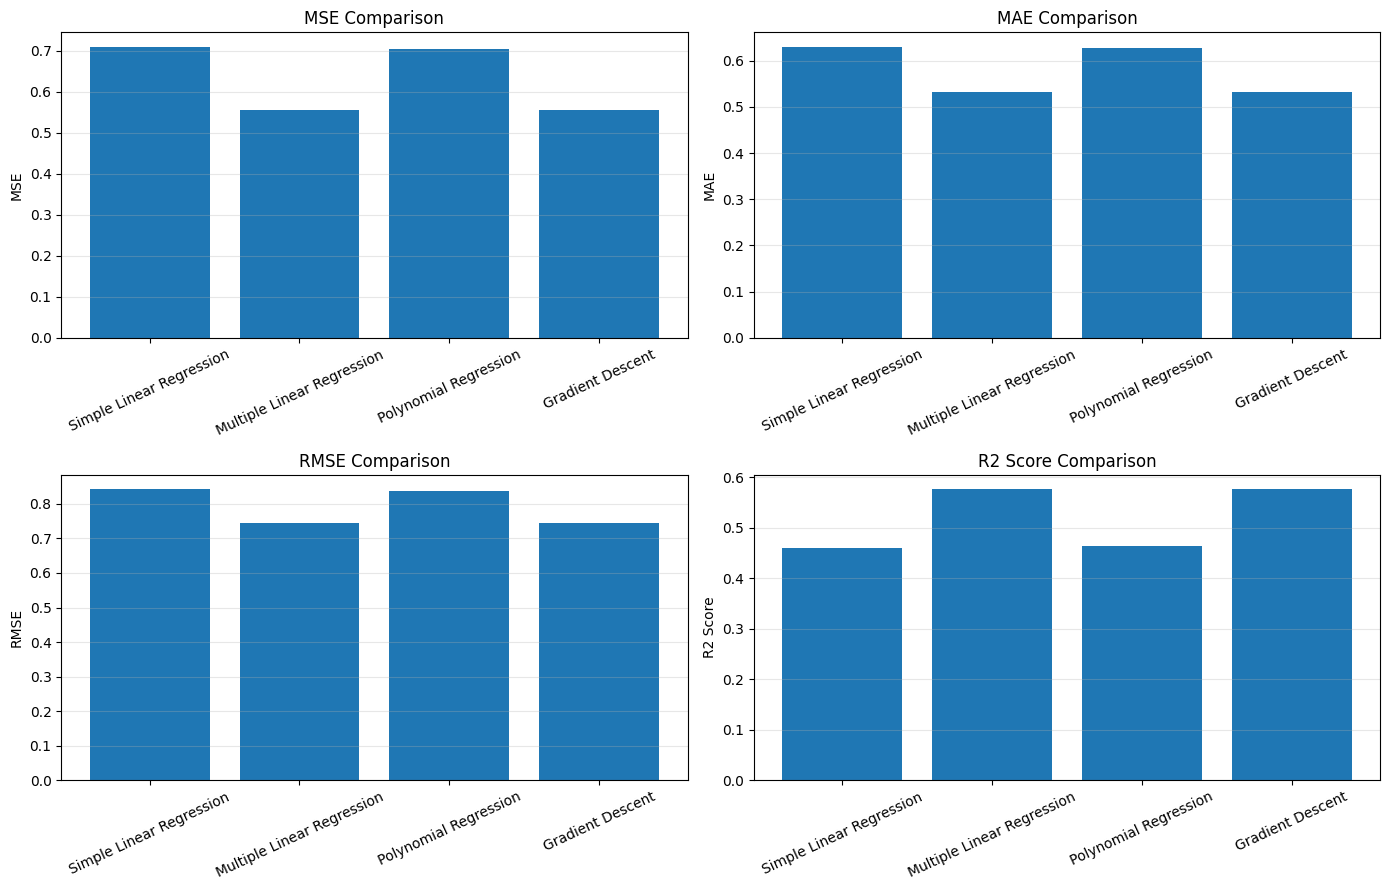

In [ ]:
# Compare all regression models visually

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

metrics = ['MSE', 'MAE', 'RMSE', 'R2 Score']

for ax, metric in zip(axes.flatten(), metrics):

    ax.bar(
        final_results['Model'],
        final_results[metric]
    )

    ax.set_title(metric + " Comparison")
    ax.set_ylabel(metric)
    ax.tick_params(axis='x', rotation=25)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

**Observation:**

The comparison graphs provide a visual understanding of the performance of different regression models.
- Simple Linear Regression provides a basic relationship using one feature.
- Multiple Linear Regression considers all available housing features.
- Polynomial Regression captures nonlinear relationships.
- Gradient Descent optimizes the parameters of Multiple Linear Regression iteratively.

---

**20. Actual vs Predicted Comparison:**

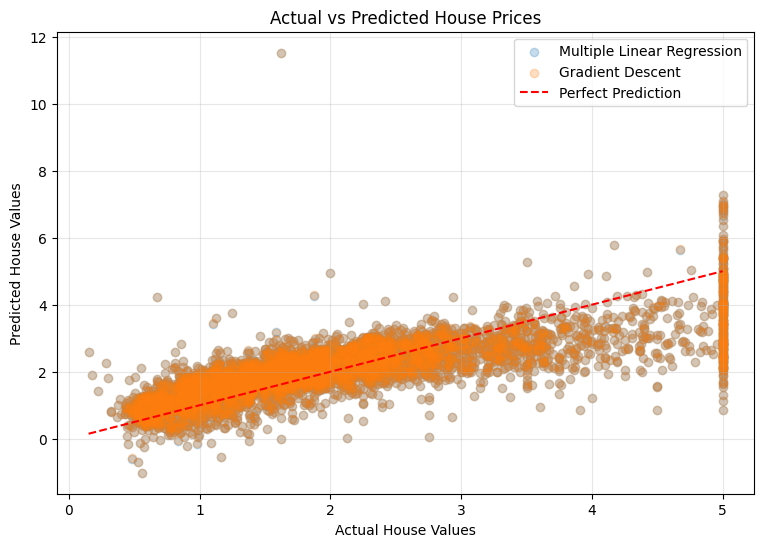

In [ ]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_test,
    y_pred_multiple,
    alpha=0.25,
    label="Multiple Linear Regression"
)

plt.scatter(
    y_test,
    y_pred_gd,
    alpha=0.25,
    label="Gradient Descent"
)

# Perfect prediction reference line

min_value = y_test.min()
max_value = y_test.max()

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    'r--',
    label="Perfect Prediction"
)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")

plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Observation:**

The closer the predicted values are to the diagonal reference line, the better the prediction accuracy. Comparing both models helps identify the effectiveness of manual Gradient Descent.

---

**21. Best Model Selection:**

In [ ]:
# Select the best model based on R2 score

best_model = final_results.loc[
    final_results['R2 Score'].idxmax()
]

print("BEST PERFORMING MODEL")

print("Model:", best_model['Model'])
print("MSE:", best_model['MSE'])
print("MAE:", best_model['MAE'])
print("RMSE:", best_model['RMSE'])
print("R2 Score:", best_model['R2 Score'])

print("\nModel selection completed!")

BEST PERFORMING MODEL
Model: Multiple Linear Regression
MSE: 0.5558915986952438
MAE: 0.5332001304956561
RMSE: 0.745581383012776
R2 Score: 0.5757877060324512

Model selection completed!


**Observation:**

The model with the highest R² score is selected as the best-performing candidate among the implemented models. Its MSE, MAE and RMSE should also be examined to ensure that its predictions have acceptable errors.

---

**22. Result and Analysis:**

**22.1. Result:**

In this experiment, different regression models were successfully developed and implemented using the California Housing Dataset.

The following models were evaluated:

1. Simple Linear Regression
2. Multiple Linear Regression
3. Polynomial Regression
4. Multiple Linear Regression using manually implemented Gradient Descent

The performance of these models was evaluated using Mean Squared Error (MSE), Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score.

Gradient Descent was successfully implemented using NumPy. The loss curve was plotted to analyze the convergence of the algorithm. Different learning rates were also tested to understand their effect on optimization.

The final comparison table was used to identify the best-performing regression model.

**22.2. Critical Analysis:**

- Simple Linear Regression is easy to understand but considers only one feature.
- Multiple Linear Regression considers multiple housing characteristics and can provide better predictive performance.
- Polynomial Regression captures nonlinear relationships but may introduce unnecessary complexity.
- Gradient Descent provides an iterative method for optimizing model parameters.
- Feature standardization improves the stability and convergence of Gradient Descent.
- A higher R² score and lower error metrics indicate better predictive performance.

**22.3. Limitations:**

1. House prices are influenced by factors that may not be completely represented in the dataset.
2. Polynomial Regression may overfit the training data.
3. Gradient Descent performance depends on the learning rate and number of iterations.
4. The dataset represents historical housing information and may not reflect current market prices.

---

**23. Conclusion:**

In this practical assignment, different regression models were developed for the real-world application of house price prediction using the California Housing Dataset.

Simple Linear Regression, Multiple Linear Regression and Polynomial Regression were implemented to understand different relationships between housing features and house prices.

The performance of the models was evaluated using MSE, MAE, RMSE and R² Score. Their results were compared to identify the most suitable regression model.

Gradient Descent was also implemented manually using NumPy to optimize the weights and bias of Linear Regression. The effect of different learning rates and iterations was analyzed using loss curves.

The experiment demonstrated that regression techniques are useful for predicting continuous numerical values and that Gradient Descent is an effective optimization algorithm when its parameters are appropriately selected.

Further improvements can include hyperparameter tuning, cross-validation, regularization and the use of additional housing features.